# Minggu 1 — IBM Telco Customer Churn
**Capstone Generative AI | 1 November 2026**

Tujuan: memuat ZIP asli, audit kualitas data, preprocessing, EDA, dan menyimpan dataset siap modeling. Target adalah `Churn Value` (1 = churn).

## 1. Upload ZIP dan baca Excel

In [1]:
import io, zipfile, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from google.colab import files
sns.set_theme(style="whitegrid")
uploaded = files.upload()  # upload archive (3).zip
zip_name = next((k for k in uploaded if k.lower().endswith('.zip')), None)
if zip_name is None:
    raise ValueError("Upload file ZIP dataset terlebih dahulu")
with zipfile.ZipFile(io.BytesIO(uploaded[zip_name])) as z:
    excel_files = [x for x in z.namelist() if x.lower().endswith('.xlsx') and not x.startswith('__MACOSX')]
    if not excel_files: raise ValueError("Tidak ada XLSX di ZIP")
    df = pd.read_excel(io.BytesIO(z.read(excel_files[0])))
print('Ukuran:', df.shape)
display(df.head())

Saving archive (3).zip to archive (3) (1).zip
Ukuran: (7043, 33)


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


## 2. Audit data awal

In [2]:
print('Kolom:', df.columns.tolist())
print('Duplikat seluruh baris:', df.duplicated().sum())
print('Duplikat CustomerID:', df['CustomerID'].duplicated().sum())
display(pd.DataFrame({'dtype': df.dtypes.astype(str), 'missing': df.isna().sum(), 'unique': df.nunique(dropna=False)}))
print('Distribusi target:')
display(df['Churn Value'].value_counts().rename(index={0:'Tidak Churn',1:'Churn'}))
print('Churn rate:', f"{df['Churn Value'].mean():.2%}")

Kolom: ['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code', 'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value', 'Churn Score', 'CLTV', 'Churn Reason']
Duplikat seluruh baris: 0
Duplikat CustomerID: 0


,dtype,missing,unique
CustomerID,object,0,7043
Count,int64,0,1
Country,object,0,1
State,object,0,1
City,object,0,1129
Zip Code,int64,0,1652
Lat Long,object,0,1652
Latitude,float64,0,1652
Longitude,float64,0,1651
Gender,object,0,2


Distribusi target:


,count
Churn Value,
Tidak Churn,5174
Churn,1869


Churn rate: 26.54%


In [3]:
clean = df.copy()
clean['Total Charges'] = pd.to_numeric(clean['Total Charges'], errors='coerce')
print('Total Charges kosong setelah konversi:', clean['Total Charges'].isna().sum())
mask_new = clean['Total Charges'].isna() & clean['Tenure Months'].eq(0)
clean.loc[mask_new, 'Total Charges'] = 0
print('Diisi 0 untuk tenure 0:', mask_new.sum())
print('Sisa missing Total Charges:', clean['Total Charges'].isna().sum())
clean['Total Charges'] = clean['Total Charges'].fillna(clean['Total Charges'].median())
clean = clean.drop_duplicates(subset='CustomerID').reset_index(drop=True)
assert clean['Churn Value'].isin([0,1]).all()
print('Ukuran data bersih:', clean.shape)

Total Charges kosong setelah konversi: 11
Diisi 0 untuk tenure 0: 11
Sisa missing Total Charges: 0
Ukuran data bersih: (7043, 33)


## 4. Exploratory Data Analysis (EDA)

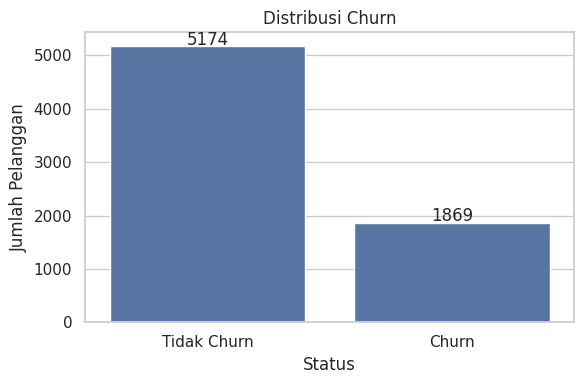

Churn rate: 26.54%


In [4]:
fig, ax = plt.subplots(figsize=(6,4))
counts = clean['Churn Value'].map({0:'Tidak Churn',1:'Churn'}).value_counts()
sns.barplot(x=counts.index, y=counts.values, ax=ax)
ax.set(title='Distribusi Churn', xlabel='Status', ylabel='Jumlah Pelanggan')
for i,v in enumerate(counts.values): ax.text(i,v+30,str(v),ha='center')
plt.tight_layout();plt.show()
print('Churn rate:', f"{clean['Churn Value'].mean():.2%}")

,Churn rate,Jumlah
Contract,,
Month-to-month,42.7%,3875
One year,11.3%,1473
Two year,2.8%,1695


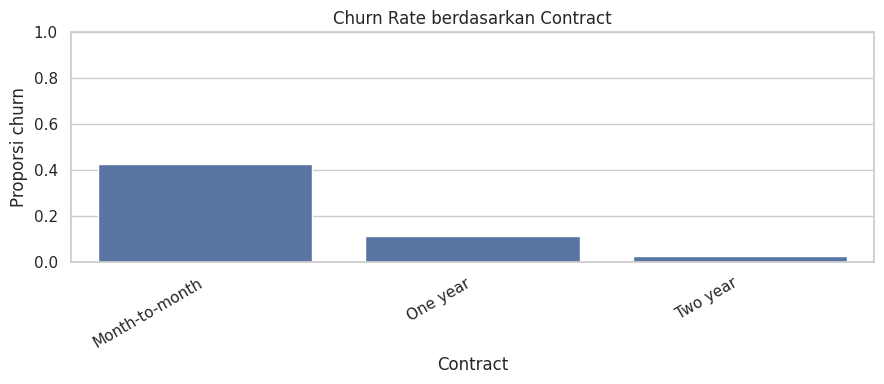

,Churn rate,Jumlah
Internet Service,,
Fiber optic,41.9%,3096
DSL,19.0%,2421
No,7.4%,1526


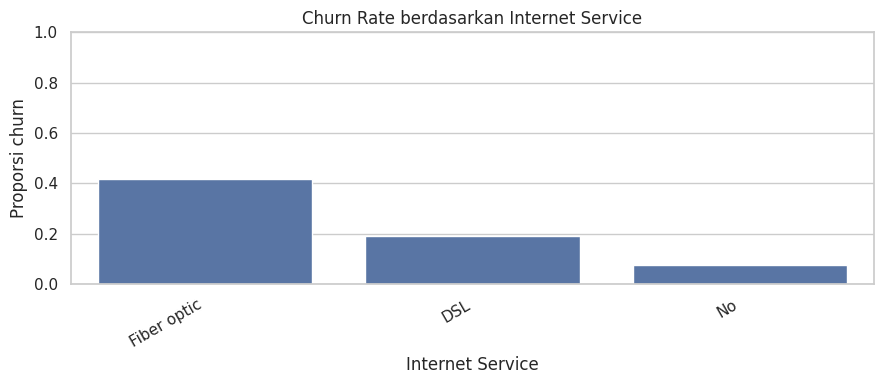

,Churn rate,Jumlah
Payment Method,,
Electronic check,45.3%,2365
Mailed check,19.1%,1612
Bank transfer (automatic),16.7%,1544
Credit card (automatic),15.2%,1522


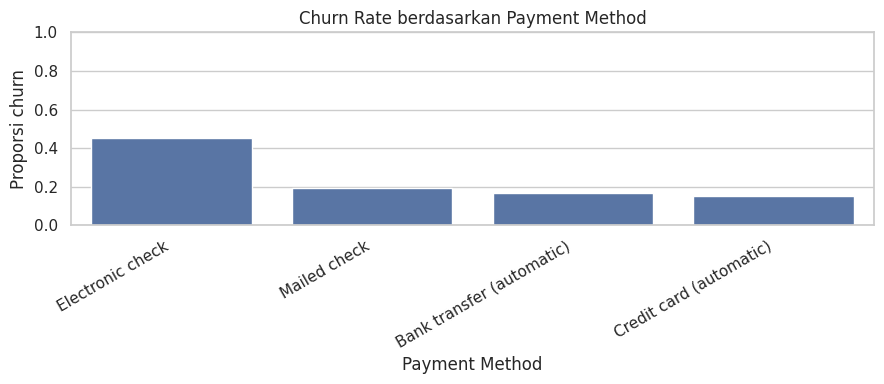

,Churn rate,Jumlah
Senior Citizen,,
Yes,41.7%,1142
No,23.6%,5901


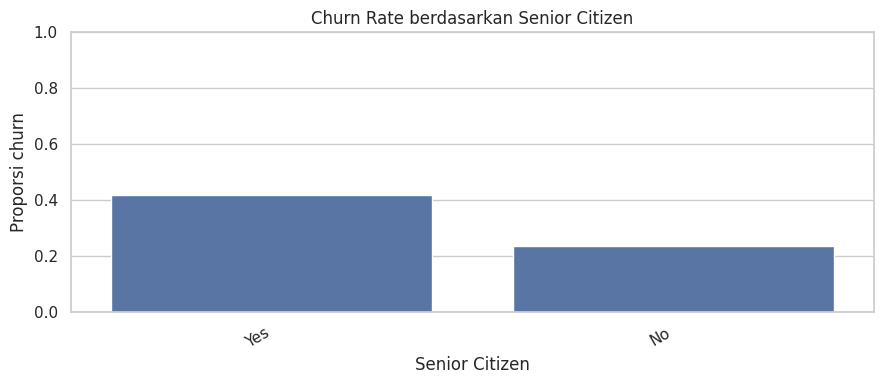

,Churn rate,Jumlah
Tech Support,,
No,41.6%,3473
Yes,15.2%,2044
No internet service,7.4%,1526


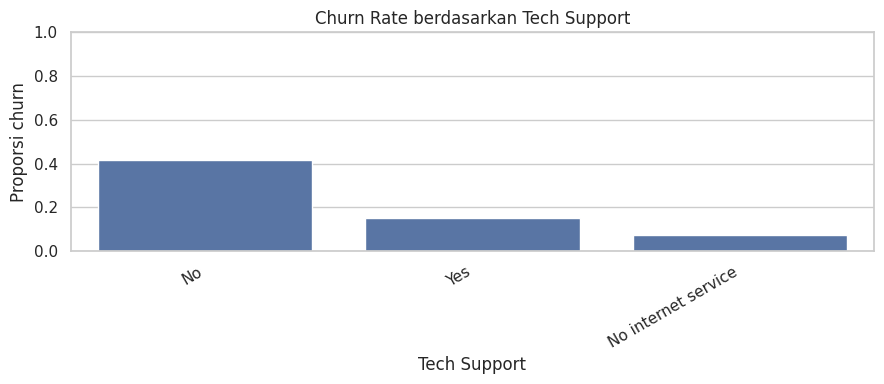

In [5]:
for col in ['Contract','Internet Service','Payment Method','Senior Citizen','Tech Support']:
    rates = clean.groupby(col)['Churn Value'].agg(['mean','count']).sort_values('mean',ascending=False)
    display(rates.rename(columns={'mean':'Churn rate','count':'Jumlah'}).style.format({'Churn rate':'{:.1%}'}))
    plt.figure(figsize=(9,4))
    sns.barplot(x=rates.index.astype(str),y=rates['mean'].values)
    plt.title('Churn Rate berdasarkan '+col);plt.ylabel('Proporsi churn');plt.xlabel(col)
    plt.xticks(rotation=30,ha='right');plt.ylim(0,1);plt.tight_layout();plt.show()

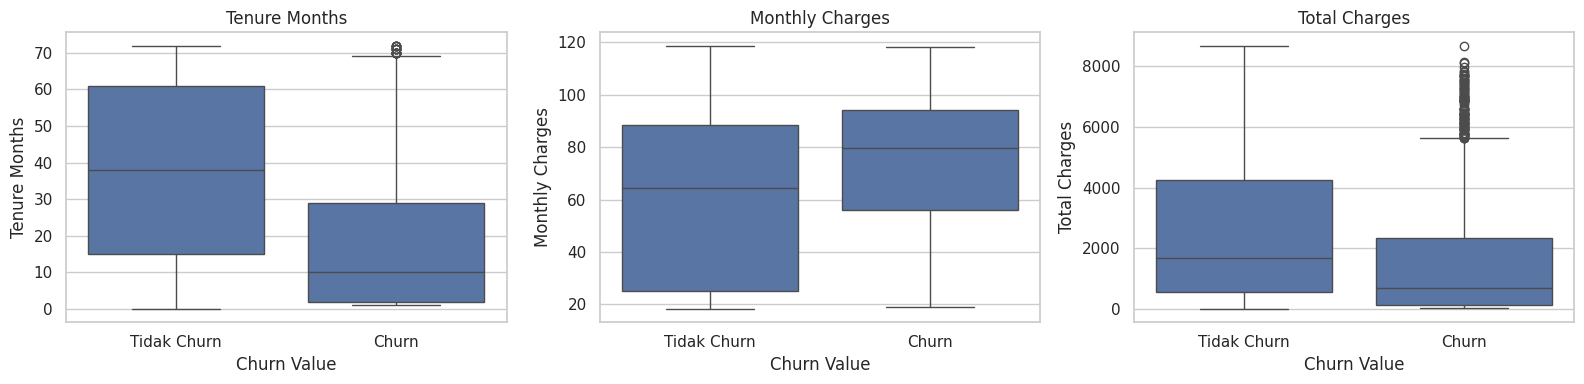

,Tenure Months,Monthly Charges,Total Charges
Churn Value,,,
0,38.0,64.425,1679.525
1,10.0,79.650,703.550


In [6]:
fig,axes=plt.subplots(1,3,figsize=(16,4))
for ax,col in zip(axes,['Tenure Months','Monthly Charges','Total Charges']):
    sns.boxplot(data=clean,x='Churn Value',y=col,ax=ax)
    ax.set_xticks([0,1],['Tidak Churn','Churn']);ax.set_title(col)
plt.tight_layout();plt.show()
display(clean.groupby('Churn Value')[['Tenure Months','Monthly Charges','Total Charges']].median())

## 5. Persiapan fitur untuk Minggu 2


In [7]:
drop_cols = ['CustomerID','Count','Country','State','City','Zip Code','Lat Long','Latitude','Longitude',
             'Churn Label','Churn Score','Churn Reason','CLTV']
model_df = clean.drop(columns=drop_cols)
assert 'Churn Value' in model_df.columns
assert not model_df.isna().any().any(), 'Masih ada missing value'
X = model_df.drop(columns=['Churn Value'])
y = model_df['Churn Value']
print('Fitur:',X.shape[1], 'Target:',y.name)
print('Kolom kategorikal:',X.select_dtypes(include=['object','category']).columns.tolist())
display(model_df.head())

Fitur: 19 Target: Churn Value
Kolom kategorikal: ['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method']


,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Value
0,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
1,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1
2,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.50,1
3,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,1
4,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.30,1


## 6. Simpan output dan ringkasan temuan

In [8]:
os.makedirs('output_minggu_1',exist_ok=True)
clean.to_csv('output_minggu_1/telco_clean_full.csv',index=False)
model_df.to_csv('output_minggu_1/telco_ready_for_modeling.csv',index=False)
summary = f"""EDA IBM Telco Churn — Minggu 1
Jumlah pelanggan: {len(clean)}
Churn: {int(y.sum())} ({y.mean():.2%})
Tidak churn: {int((1-y).sum())}
Jumlah fitur untuk model: {X.shape[1]}
Missing pada dataset model: {int(model_df.isna().sum().sum())}

Catatan: kategori belum di-encode. Minggu 2 lakukan stratified train/test split,
fit preprocessing hanya pada training menggunakan ColumnTransformer/Pipeline,
kemudian evaluasi precision, recall, F1-score, ROC-AUC.
"""
print(summary)
with open('output_minggu_1/ringkasan.txt','w') as f:f.write(summary)
import shutil
shutil.make_archive('hasil_minggu_1','zip','output_minggu_1')
files.download('hasil_minggu_1.zip')

EDA IBM Telco Churn — Minggu 1
Jumlah pelanggan: 7043
Churn: 1869 (26.54%)
Tidak churn: 5174
Jumlah fitur untuk model: 19
Missing pada dataset model: 0

Catatan: kategori belum di-encode. Minggu 2 lakukan stratified train/test split,
fit preprocessing hanya pada training menggunakan ColumnTransformer/Pipeline,
kemudian evaluasi precision, recall, F1-score, ROC-AUC.



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

UPLOAD DATASET MINGGU 1 ATAU DATASET IBM ASLI


Saving hasil_minggu_1.zip to hasil_minggu_1 (1).zip
Dataset dipilih: dataset_minggu_2/telco_clean_full.csv

Ukuran dataset: (7043, 33)


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.50,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.30,Yes,1,89,5340,Competitor had better devices



Distribusi target:
Churn Value
0    5174
1    1869
Name: count, dtype: int64

Persentase:
Churn Value
0    73.46
1    26.54
Name: proportion, dtype: float64

Jumlah fitur: 21
Fitur: ['Country', 'State', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges']

TRAIN TEST SPLIT
Training: (5634, 21)
Testing : (1409, 21)

Distribusi Training:
Churn Value
0    0.7346
1    0.2654
Name: proportion, dtype: float64

Distribusi Testing:
Churn Value
0    0.7346
1    0.2654
Name: proportion, dtype: float64

Fitur numerik: ['Tenure Months', 'Monthly Charges', 'Total Charges']

Fitur kategorikal: ['Country', 'State', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Securit

,Model,CV F1 Mean,CV F1 Std,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.6395,0.0215,0.7424,0.5096,0.7781,0.6159,0.8489
1,Gradient Boosting,0.6117,0.0219,0.8055,0.6645,0.5401,0.5959,0.8544
2,Random Forest,0.5680,0.0215,0.7928,0.6367,0.5107,0.5668,0.8328


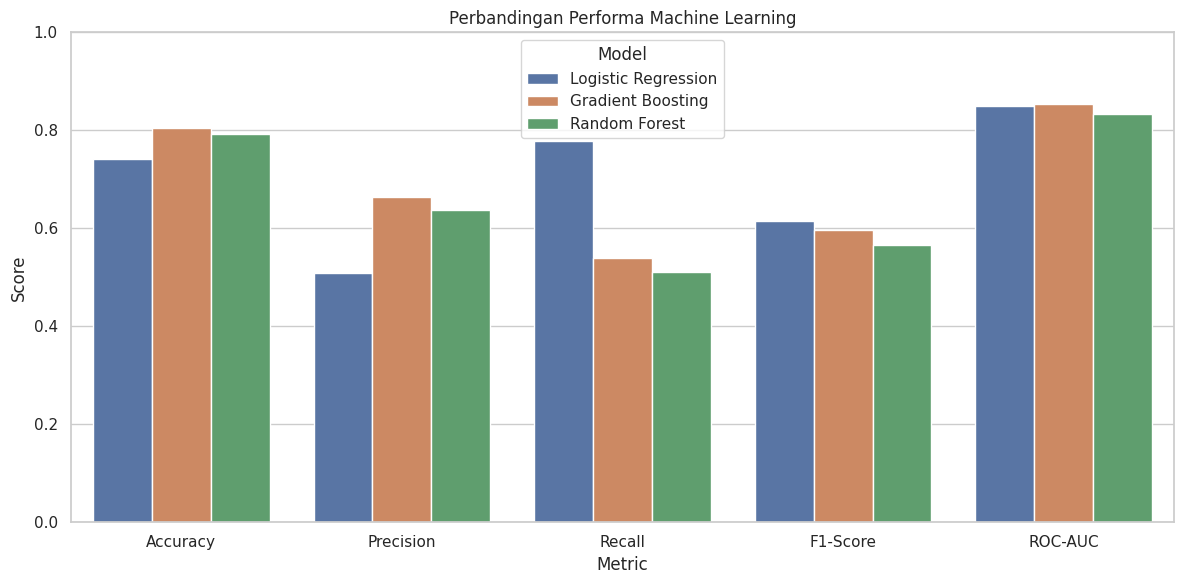

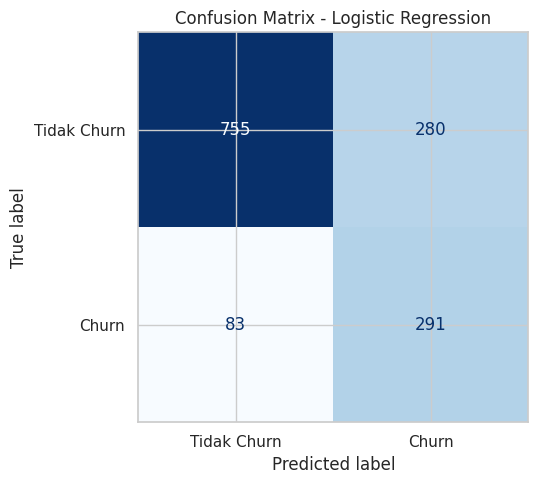

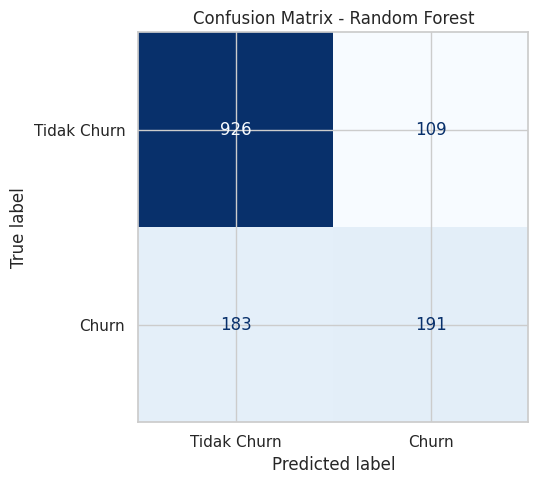

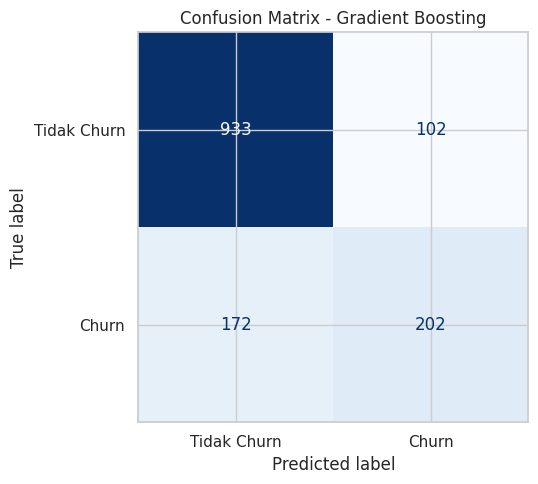

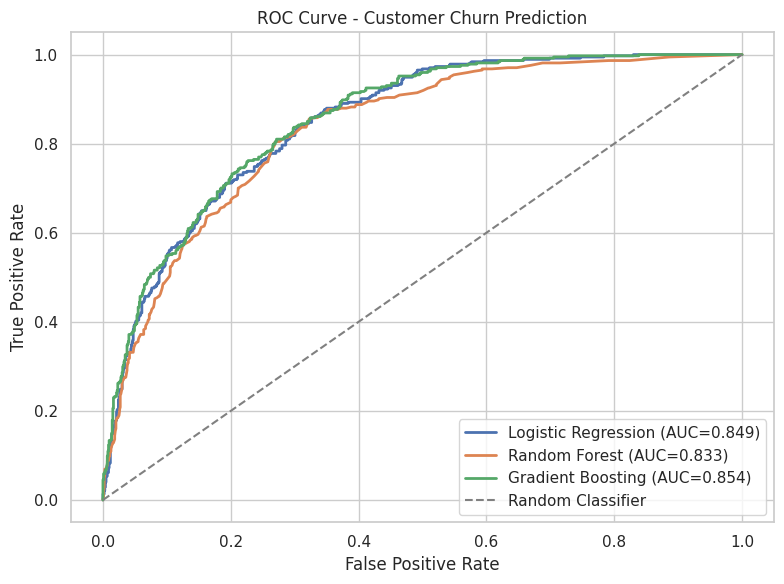


MODEL TERBAIK: Logistic Regression
Model         Logistic Regression
CV F1 Mean               0.639525
CV F1 Std                0.021455
Accuracy                  0.74237
Precision                0.509632
Recall                   0.778075
F1-Score                 0.615873
ROC-AUC                  0.848929

Model berhasil disimpan.


,Feature,Importance
0,numeric__Tenure Months,1.210366
12,categorical__Dependents_Yes,0.906442
41,categorical__Contract_Two year,0.731630
11,categorical__Dependents_No,0.724264
39,categorical__Contract_Month-to-month,0.666607
19,categorical__Internet Service_Fiber optic,0.600173
1,numeric__Monthly Charges,0.552388
18,categorical__Internet Service_DSL,0.541861
2,numeric__Total Charges,0.512368
42,categorical__Paperless Billing_No,0.250625


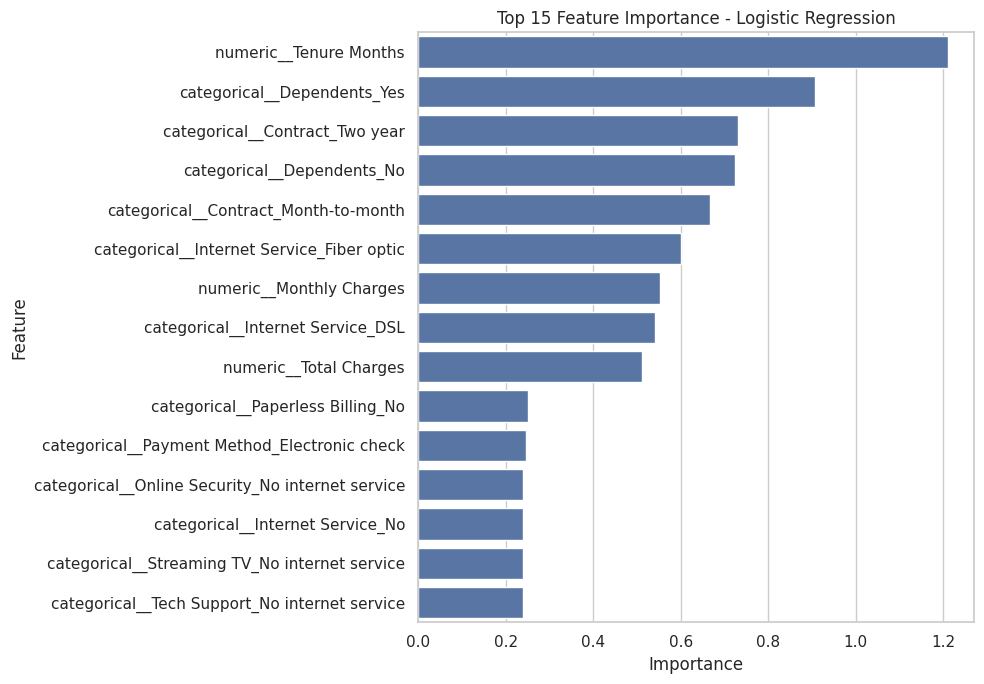


CONTOH HASIL PREDIKSI


,Country,State,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,...,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Actual_Churn,Predicted_Churn,Churn_Probability,Prediction_Status
2196,United States,California,Male,No,Yes,No,72,Yes,Yes,Fiber optic,...,Yes,Two year,Yes,Credit card (automatic),114.05,8468.20,0,0,0.186324,Tidak Churn
3549,United States,California,Female,Yes,No,No,8,Yes,Yes,Fiber optic,...,Yes,Month-to-month,Yes,Credit card (automatic),100.15,908.55,0,1,0.843710,Churn
3515,United States,California,Female,No,Yes,No,41,Yes,Yes,DSL,...,No,One year,Yes,Credit card (automatic),78.35,3211.20,0,0,0.236000,Tidak Churn
5162,United States,California,Male,No,Yes,No,18,Yes,No,Fiber optic,...,No,Month-to-month,No,Electronic check,78.20,1468.75,0,1,0.724027,Churn
4642,United States,California,Female,No,Yes,No,72,Yes,Yes,DSL,...,Yes,Two year,Yes,Credit card (automatic),82.65,5919.35,0,0,0.084998,Tidak Churn
6096,United States,California,Female,No,No,No,21,Yes,Yes,Fiber optic,...,Yes,Month-to-month,Yes,Credit card (automatic),99.85,1992.55,0,1,0.813851,Churn
4504,United States,California,Female,No,No,No,21,Yes,No,Fiber optic,...,Yes,Month-to-month,Yes,Bank transfer (automatic),99.15,1956.40,0,1,0.707959,Churn
4067,United States,California,Male,No,No,Yes,19,Yes,Yes,No,...,No internet service,Month-to-month,Yes,Credit card (automatic),24.10,439.20,0,0,0.109813,Tidak Churn
6233,United States,California,Female,No,Yes,Yes,61,Yes,No,No,...,No internet service,Two year,No,Credit card (automatic),19.75,1311.60,0,0,0.003348,Tidak Churn
430,United States,California,Male,Yes,No,No,17,Yes,No,DSL,...,No,Month-to-month,Yes,Electronic check,45.05,770.60,1,1,0.653016,Churn



TELECOM CUSTOMER CHURN PREDICTION
MINGGU 2 - MACHINE LEARNING

Jumlah data: 7043
Jumlah fitur: 21

Data Training: 5634
Data Testing: 1409

Split: 80% Training, 20% Testing
Cross Validation: Stratified 5-Fold

Model yang diuji:
1. Logistic Regression
2. Random Forest
3. Gradient Boosting

Model terbaik berdasarkan F1-Score kelas Churn:
Logistic Regression

Accuracy : 0.7424
Precision: 0.5096
Recall   : 0.7781
F1-Score : 0.6159
ROC-AUC  : 0.8489

Catatan:
Hasil evaluasi berasal dari data testing.
Model dipilih berdasarkan F1-score testing.
Untuk evaluasi final yang lebih ketat, pemilihan
model sebaiknya berdasarkan cross-validation
atau validation set terpisah.


SEMUA PROSES SELESAI!
File output: hasil_minggu_2.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:


# Machine Learning Modeling & Evaluation

!pip -q install openpyxl joblib scikit-learn seaborn

import os
import zipfile
import shutil
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

OUTPUT_DIR = "hasil_minggu_2"
os.makedirs(OUTPUT_DIR, exist_ok=True)

RANDOM_STATE = 42

# 1. UPLOAD DATASET

print("UPLOAD DATASET MINGGU 1 ATAU DATASET IBM ASLI")
uploaded = files.upload()

upload_name = next(iter(uploaded))

if upload_name.lower().endswith(".zip"):
    extract_dir = "dataset_minggu_2"
    os.makedirs(extract_dir, exist_ok=True)

    with zipfile.ZipFile(upload_name, "r") as z:
        z.extractall(extract_dir)

    data_files = []

    for root, dirs, filenames in os.walk(extract_dir):
        for filename in filenames:
            if filename.lower().endswith((".csv", ".xlsx")):
                data_files.append(
                    os.path.join(root, filename)
                )

    if not data_files:
        raise ValueError("Tidak ada CSV/XLSX di dalam ZIP.")

    # Prioritas dataset yang sudah dibersihkan.
    priority = [
        "telco_clean_full.csv",
        "telco_ready_for_modeling.csv",
        "telco_customer_churn.xlsx"
    ]

    def file_priority(path):
        name = os.path.basename(path).lower()
        return (
            priority.index(name)
            if name in priority
            else len(priority)
        )

    data_path = sorted(
        data_files,
        key=file_priority
    )[0]

else:
    data_path = upload_name

print("Dataset dipilih:", data_path)

if data_path.lower().endswith(".csv"):
    df = pd.read_csv(data_path)
else:
    df = pd.read_excel(data_path)

print("\nUkuran dataset:", df.shape)
display(df.head())


# 2. DATA PREPARATION

df.columns = df.columns.str.strip()

# Normalisasi nama kolom agar kompatibel
# dengan variasi file Minggu 1.

target_candidates = [
    "Churn Value",
    "Churn",
    "churn",
    "churn_value",
    "target"
]

target_col = next(
    (c for c in target_candidates if c in df.columns),
    None
)

if target_col is None:
    raise ValueError(
        "Kolom target churn tidak ditemukan. "
        f"Kolom tersedia: {df.columns.tolist()}"
    )

# Konversi target menjadi biner 0 dan 1.

target_raw = df[target_col]

if pd.api.types.is_numeric_dtype(target_raw):
    y = pd.to_numeric(target_raw, errors="coerce")
else:
    y = (
        target_raw.astype(str)
        .str.strip()
        .str.lower()
        .map({
            "yes": 1,
            "no": 0,
            "churn": 1,
            "tidak churn": 0,
            "1": 1,
            "0": 0,
            "true": 1,
            "false": 0
        })
    )

valid_rows = y.isin([0, 1])

df = df.loc[valid_rows].copy()
y = y.loc[valid_rows].astype(int)



leakage_cols = [
    "Churn Value",
    "Churn Label",
    "Churn Reason",
    "Churn Score",
    "Churn",
    "churn",
    "churn_value",
    "target",
    "CLTV",
    "CustomerID",
    "Customer ID",
    "customerID",
    "Count",
    "Lat Long",
    "Latitude",
    "Longitude",
    "Zip Code",
    "City"
]

drop_cols = [
    c for c in leakage_cols
    if c in df.columns
]

X = df.drop(columns=drop_cols)

# Total Charges kadang mengandung string kosong.
if "Total Charges" in X.columns:
    X["Total Charges"] = pd.to_numeric(
        X["Total Charges"],
        errors="coerce"
    )

# Hindari kolom kosong sepenuhnya.
X = X.dropna(axis=1, how="all")

# Hindari fitur ID atau kolom objek unik per pelanggan.
unique_ratio = X.nunique(dropna=True) / len(X)

id_like_cols = [
    c for c in X.columns
    if (
        X[c].dtype == "object"
        and unique_ratio[c] > 0.95
    )
]

X = X.drop(columns=id_like_cols)

print("\nDistribusi target:")
print(y.value_counts())
print("\nPersentase:")
print((y.value_counts(normalize=True) * 100).round(2))

print("\nJumlah fitur:", X.shape[1])
print("Fitur:", X.columns.tolist())


# 3. TRAIN TEST SPLIT (80:20)


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("\nTRAIN TEST SPLIT")
print("Training:", X_train.shape)
print("Testing :", X_test.shape)

print("\nDistribusi Training:")
print(y_train.value_counts(normalize=True).round(4))

print("\nDistribusi Testing:")
print(y_test.value_counts(normalize=True).round(4))


# 4. PREPROCESSING PIPELINE


numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="most_frequent"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("\nFitur numerik:", numeric_features)
print("\nFitur kategorikal:", categorical_features)


# 5. DEFINISI MODEL


models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=RANDOM_STATE
    )
}


# 6. TRAINING DAN CROSS VALIDATION


results = []
trained_models = {}
predictions = {}
probabilities = {}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

for model_name, classifier in models.items():

    print("\n" + "=" * 60)
    print("TRAINING:", model_name)
    print("=" * 60)

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    # Cross-validation hanya pada data training.
    cv_scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="f1",
        n_jobs=-1
    )

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_proba = pipeline.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )
    roc_auc = roc_auc_score(y_test, y_proba)

    results.append({
        "Model": model_name,
        "CV F1 Mean": cv_scores.mean(),
        "CV F1 Std": cv_scores.std(),
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": roc_auc
    })

    trained_models[model_name] = pipeline
    predictions[model_name] = y_pred
    probabilities[model_name] = y_proba

    print("\nCross Validation F1:", round(cv_scores.mean(), 4))
    print("Accuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1-Score :", round(f1, 4))
    print("ROC-AUC  :", round(roc_auc, 4))

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=["Tidak Churn", "Churn"],
        zero_division=0
    ))


# 7. PERBANDINGAN HASIL MODEL


results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by=["F1-Score", "ROC-AUC"],
    ascending=False
).reset_index(drop=True)

print("\nHASIL EVALUASI MODEL")
display(results_df.round(4))

results_df.to_csv(
    f"{OUTPUT_DIR}/perbandingan_model.csv",
    index=False
)

metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]

plot_df = results_df.melt(
    id_vars="Model",
    value_vars=metrics_to_plot,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=plot_df,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Perbandingan Performa Machine Learning")
plt.ylim(0, 1)
plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/perbandingan_model.png",
    dpi=200
)
plt.show()


# 8. CONFUSION MATRIX SETIAP MODEL


for model_name in models:

    cm = confusion_matrix(
        y_test,
        predictions[model_name],
        labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Tidak Churn", "Churn"]
    )

    fig, ax = plt.subplots(figsize=(6, 5))

    disp.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(f"Confusion Matrix - {model_name}")

    plt.tight_layout()

    safe_name = model_name.lower().replace(" ", "_")

    plt.savefig(
        f"{OUTPUT_DIR}/confusion_matrix_{safe_name}.png",
        dpi=200
    )
    plt.show()


# 9. ROC CURVE


plt.figure(figsize=(8, 6))

for model_name in models:

    fpr, tpr, thresholds = roc_curve(
        y_test,
        probabilities[model_name]
    )

    auc_score = roc_auc_score(
        y_test,
        probabilities[model_name]
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{model_name} (AUC={auc_score:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Customer Churn Prediction")
plt.legend()
plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/roc_curve.png",
    dpi=200
)
plt.show()


# 10. PILIH MODEL TERBAIK


best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("\n" + "=" * 60)
print("MODEL TERBAIK:", best_model_name)
print("=" * 60)

print(results_df.iloc[0].to_string())

joblib.dump(
    best_model,
    f"{OUTPUT_DIR}/best_churn_model.joblib"
)

print("\nModel berhasil disimpan.")


# 11. FEATURE IMPORTANCE


feature_names = best_model.named_steps[
    "preprocessor"
].get_feature_names_out()

classifier = best_model.named_steps["classifier"]

if hasattr(classifier, "feature_importances_"):

    importance_values = classifier.feature_importances_

elif hasattr(classifier, "coef_"):

    importance_values = np.abs(classifier.coef_[0])

else:
    importance_values = None

if importance_values is not None:

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importance_values
    }).sort_values(
        "Importance",
        ascending=False
    )

    display(importance_df.head(15))

    importance_df.to_csv(
        f"{OUTPUT_DIR}/feature_importance.csv",
        index=False
    )

    plt.figure(figsize=(10, 7))

    sns.barplot(
        data=importance_df.head(15),
        x="Importance",
        y="Feature"
    )

    plt.title(
        f"Top 15 Feature Importance - {best_model_name}"
    )

    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/feature_importance.png",
        dpi=200
    )
    plt.show()


# 12. SIMPAN HASIL PREDIKSI


prediction_df = X_test.copy()

prediction_df["Actual_Churn"] = y_test.values

prediction_df["Predicted_Churn"] = predictions[
    best_model_name
]

prediction_df["Churn_Probability"] = probabilities[
    best_model_name
]

prediction_df["Prediction_Status"] = np.where(
    prediction_df["Predicted_Churn"] == 1,
    "Churn",
    "Tidak Churn"
)

prediction_df.to_csv(
    f"{OUTPUT_DIR}/hasil_prediksi_churn.csv",
    index=False
)

print("\nCONTOH HASIL PREDIKSI")
display(prediction_df.head(10))


# 13. RINGKASAN EKSPERIMEN


best_row = results_df.iloc[0]

summary = f"""
TELECOM CUSTOMER CHURN PREDICTION
MINGGU 2 - MACHINE LEARNING

Jumlah data: {len(df)}
Jumlah fitur: {X.shape[1]}

Data Training: {len(X_train)}
Data Testing: {len(X_test)}

Split: 80% Training, 20% Testing
Cross Validation: Stratified 5-Fold

Model yang diuji:
1. Logistic Regression
2. Random Forest
3. Gradient Boosting

Model terbaik berdasarkan F1-Score kelas Churn:
{best_model_name}

Accuracy : {best_row['Accuracy']:.4f}
Precision: {best_row['Precision']:.4f}
Recall   : {best_row['Recall']:.4f}
F1-Score : {best_row['F1-Score']:.4f}
ROC-AUC  : {best_row['ROC-AUC']:.4f}

Catatan:
Hasil evaluasi berasal dari data testing.
Model dipilih berdasarkan F1-score testing.
Untuk evaluasi final yang lebih ketat, pemilihan
model sebaiknya berdasarkan cross-validation
atau validation set terpisah.
"""

with open(
    f"{OUTPUT_DIR}/ringkasan_evaluasi.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write(summary)

print(summary)


# 14. ZIP SEMUA HASIL

zip_name = "hasil_minggu_2.zip"

with zipfile.ZipFile(
    zip_name,
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    for root, dirs, filenames in os.walk(OUTPUT_DIR):
        for filename in filenames:

            file_path = os.path.join(root, filename)

            zipf.write(
                file_path,
                arcname=os.path.relpath(
                    file_path,
                    OUTPUT_DIR
                )
            )

print("\nSEMUA PROSES SELESAI!")
print("File output:", zip_name)

files.download(zip_name)
